Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 49, 861, 16)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 23, 429, 32)    │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 214, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 11, 214, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 213, 64)    │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 105, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 2, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,312 (169.19 KB)

 Trainable params: 43,312 (169.19 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
[0]	validation_0-mlogloss:1.67056
[1]	validation_0-mlogloss:1.56404


C:\Users\Lenovo\anaconda3\Lib\site-packages\xgboost\core.py:160: UserWarning: [17:44:27] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0b3782d1791676daf-1\xgboost\xgboost-ci-windows\src\learner.cc:742: 
Parameters: { "scale_pos_weight" } are not used.

  warnings.warn(smsg, UserWarning)


[2]	validation_0-mlogloss:1.46955
[3]	validation_0-mlogloss:1.38388
[4]	validation_0-mlogloss:1.30941
[5]	validation_0-mlogloss:1.24088
[6]	validation_0-mlogloss:1.17914
[7]	validation_0-mlogloss:1.12303
[8]	validation_0-mlogloss:1.07031
[9]	validation_0-mlogloss:1.02270
[10]	validation_0-mlogloss:0.97871
[11]	validation_0-mlogloss:0.93747
[12]	validation_0-mlogloss:0.89958
[13]	validation_0-mlogloss:0.86347
[14]	validation_0-mlogloss:0.83066
[15]	validation_0-mlogloss:0.80054
[16]	validation_0-mlogloss:0.77103
[17]	validation_0-mlogloss:0.74480
[18]	validation_0-mlogloss:0.71948
[19]	validation_0-mlogloss:0.69462
[20]	validation_0-mlogloss:0.67247
[21]	validation_0-mlogloss:0.65178
[22]	validation_0-mlogloss:0.63156
[23]	validation_0-mlogloss:0.61369
[24]	validation_0-mlogloss:0.59511
[25]	validation_0-mlogloss:0.57748
[26]	validation_0-mlogloss:0.56046
[27]	validation_0-mlogloss:0.54497
[28]	validation_0-mlogloss:0.53084
[29]	validation_0-mlogloss:0.51687
[30]	validation_0-mlogloss:0

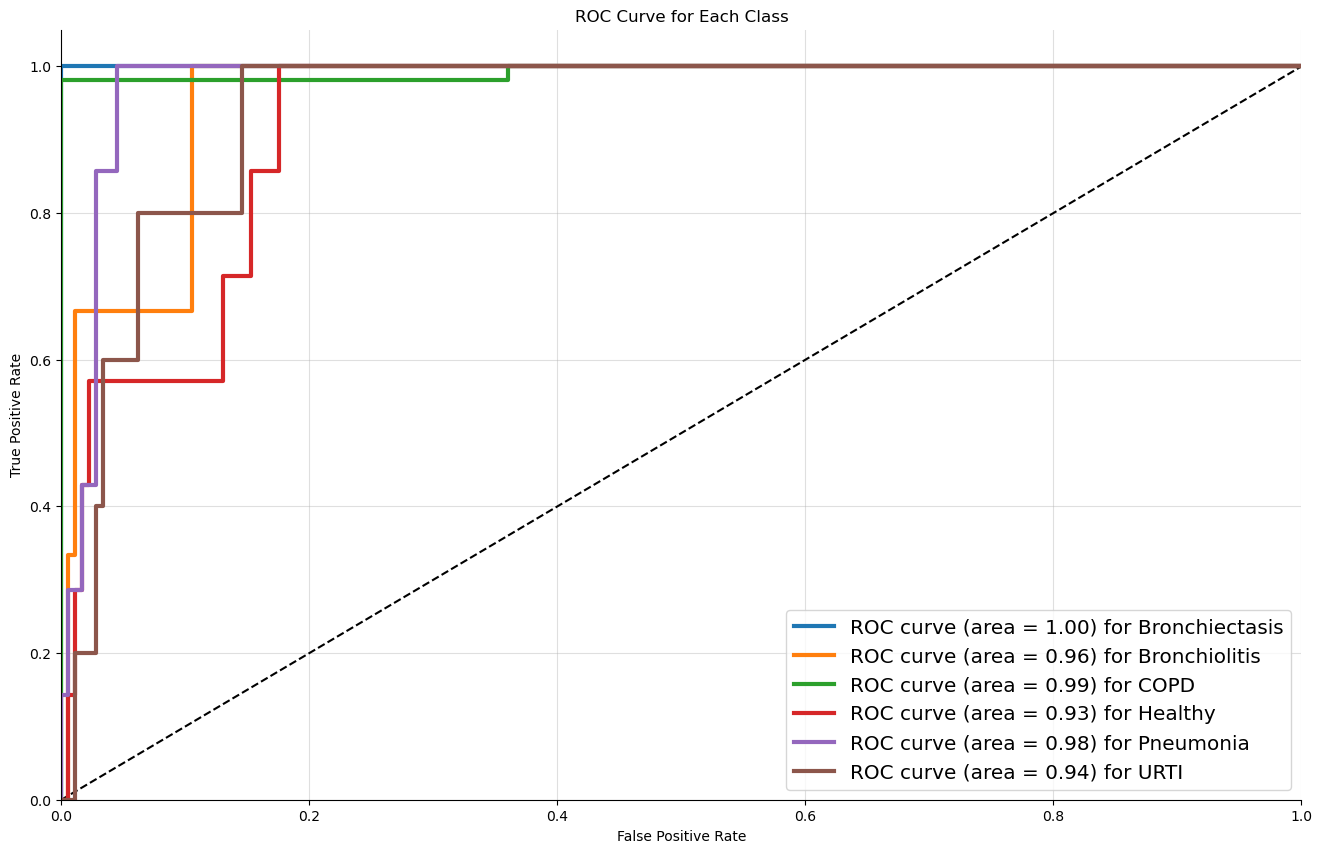

In [1]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE  # For handling class imbalance

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        
        # Extract MFCCs
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        pad_width_mfcc = max_pad_len - mfccs.shape[1]
        mfccs = np.pad(mfccs, pad_width=((0, 0), (0, pad_width_mfcc)), mode='constant')
        
        # Extract Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(y=audio, sr=sample_rate)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sample_rate)
        spectral_contrast = librosa.feature.spectral_contrast(y=audio, sr=sample_rate)
        spectral_rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sample_rate)
        
        # Pad spectral features to match MFCC length
        def pad_feature(feature, target_length):
            pad_width = target_length - feature.shape[1]
            return np.pad(feature, pad_width=((0, 0), (0, pad_width)), mode='constant')
        
        spectral_centroid = pad_feature(spectral_centroid, max_pad_len)
        spectral_bandwidth = pad_feature(spectral_bandwidth, max_pad_len)
        spectral_contrast = pad_feature(spectral_contrast, max_pad_len)
        spectral_rolloff = pad_feature(spectral_rolloff, max_pad_len)
        
        # Combine all features
        combined_features = np.vstack([mfccs, spectral_centroid, spectral_bandwidth, spectral_contrast, spectral_rolloff])
        
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return combined_features

filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN
# Combined features have shape (num_features, max_pad_len)
features1 = np.reshape(features1, (*features1.shape, 1))

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
num_rows = features1.shape[1]  # Number of combined features
num_columns = max_pad_len      # Time steps
num_channels = 1               # Single channel for grayscale-like input
filter_size = 2

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling2D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN with reduced batch size
x_train_features = cnn_model.predict(x_train, batch_size=32)  # Reduce batch size
x_test_features = cnn_model.predict(x_test, batch_size=32)

# Flatten the features for XGBoost
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for XGBoost
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Handle class imbalance using SMOTE
smote = SMOTE(random_state=42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train_features, y_train)

# Calculate class weights for XGBoost
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_resampled), y=y_train_resampled)
scale_pos_weight = {i: weight for i, weight in enumerate(class_weights)}

# XGBoost model with adjusted hyperparameters and class weights
xgb_model = xgb.XGBClassifier(
    n_estimators=200,  # Increase number of trees
    max_depth=6,       # Deeper trees
    learning_rate=0.05,  # Lower learning rate
    subsample=0.9,     # Use 90% of data for training each tree
    colsample_bytree=0.8,  # Fraction of features used per tree
    gamma=0.1,        # Regularization parameter
    scale_pos_weight=scale_pos_weight,  # Class weights to handle imbalance
    use_label_encoder=False,
    eval_metric='mlogloss',
    early_stopping_rounds=10  # Early stopping
)

# Train the XGBoost model
xgb_model.fit(x_train_resampled, y_train_resampled, eval_set=[(x_test_features, y_test)], verbose=True)

# Evaluate model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Classification report and confusion matrix
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()